# Discretization calibration {#sec-calibration}

In this section, we run error tests to determine which reward sensitivity $\sigma$ to choose in each environment. These results also give us insights into the effect of discretization on strategy. We run these tests on our three main environments:
* two-armed bandit task;
* risk-reward dilemma;
* stag-hunt game;

First, we import what we need.

In [ ]:
# general imports

import numpy as np

import jax.numpy as jnp

import matplotlib.pyplot as plt
import matplotlib as mpl

import pandas as pd
import seaborn as sns

In [ ]:
# pyCRLD imports

# Agents
from pyCRLD.Agents.Base import abase
from pyCRLD.Agents.StrategySARSA import stratSARSA
from pyCRLD.Agents.StrategyActorCritic import stratAC


In [ ]:

# Environments
from pyDDRL.Environments.SocialDilemma import SocialDilemma
from pyDDRL.Environments.RiskRewardDilemma import RiskRewardDilemma
from pyDDRL.Environments.TwoArmedBandit import TwoArmedBandit

In [ ]:
# DDRL imports

from pyDDRL.Agents.DDRLBase import DDRLBase
from pyDDRL.Agents.DDRLSarsa import DDRLSarsa
from pyDDRL.Agents.DDRLActorCritic import DDRLActorCritic

## Errors on a two-armed bandit task

Here, we compare a distributional and a non-distributional SARSA agent playing a "rich" two-armed bandit task ($p_1 = 0.9$, $p_2 = 0.7$) and a "poor" two-armed bandit task ($p_1 = 0.3$, $p_2 = 0.1$). The error at $X$ is defined as the norm of the difference between the temporal difference error of a distributional agent and that of a non-distributional agent for a given strategy $X$. We compute the error for different strategies $X$, and plot the mean error as a function of reward sensitivity $\sigma$. In @sec-results , we will select the reward sensitivity that minimizes the error in order to compute our results.

First, we define a "poor" and a "rich" environment:

In [ ]:
# Poor environment

xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.7, 0.3],
               [0.9, 0.1]])
env_poor = TwoArmedBandit(disttype='discrete', xs=xs, ps=ps)

In [ ]:
# Rich environment

xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.1, 0.9],
               [0.3, 0.7]])
env_rich = TwoArmedBandit(disttype='discrete', xs=xs, ps=ps)

Now we define the reward sensitivities that we are going to compare, as well as the strategies for which we will compute the error:

In [ ]:
# List of sigmas to compare
sigmas = np.linspace(0.0001, 1., 40)

# Sample strategies
Xs = np.linspace(0.01, 0.99, 11)

Here is the function that will allow us to compute the error:

In [ ]:
# Function to compute mean error

def compute_mean_error(env, Xs, sigmas, path, version):
    errors = np.zeros((len(sigmas), len(Xs)))
    for j, sigma in enumerate(sigmas):  # loop over sigmas
        print("sigma = "+str(sigma))
        # non-distributional agent
        mae = stratSARSA(env=env, learning_rates=0.1, 
                         discount_factors=0, choice_intensities=4., use_prefactor=True)
        
        # distributional agent
        aei = DDRLSarsa(env, nr_reward_bins=29, discretization_sigma=sigma, 
                        learning_rates=0.1, discount_factors=0, 
                        choice_intensities=4, Rmin=-1, Rmax=1,
                        method="weights", wU=1, use_prefactor=True)
        
        for k, x in enumerate(Xs):  # loop over strategies
            # strategy X
            X = np.zeros((1, 1, 2))
            X[:, :, 0] = x
            X[:, :, 1] = 1 - x

            # TDe for distributional agent
            distRPE = aei.TDerror(X, norm=True)

            # TDe for non-distributional agent
            detRPE = mae.TDerror(X, norm=True)

            # compute the error
            error = np.linalg.norm(detRPE-distRPE) 
            errors[j, k] = error
    
    # compute the mean error
    mean_error = np.mean(errors, axis=-1)

    # put results into df and save
    columns = ["X="+str(x) for x in Xs]
    index = ["sigma="+str(sigma) for sigma in sigmas]
    df = pd.DataFrame(errors, index=index, columns=columns)
    df.to_csv(path+"tab_error_df_"+version+".csv")
    return mean_error

In [ ]:
# Path and version
path = "../data/error_calculation/"
version_poor = "poor_v1"
version_rich = "rich_v1"

In [ ]:
#| eval: false
# Compute mean error for poor and rich envs
mean_err_poor = compute_mean_error(env_poor, Xs, sigmas, path, version_poor)
mean_err_rich = compute_mean_error(env_rich, Xs, sigmas, path, version_rich)

sigma = 0.0001
sigma = 0.025738461538461536
sigma = 0.05137692307692308
sigma = 0.07701538461538461
sigma = 0.10265384615384615
sigma = 0.12829230769230768
sigma = 0.1539307692307692
sigma = 0.17956923076923076
sigma = 0.20520769230769229
sigma = 0.2308461538461538
sigma = 0.25648461538461537
sigma = 0.2821230769230769
sigma = 0.3077615384615384
sigma = 0.3334
sigma = 0.35903846153846153
sigma = 0.384676923076923
sigma = 0.4103153846153846
sigma = 0.43595384615384614
sigma = 0.46159230769230764
sigma = 0.4872307692307692
sigma = 0.5128692307692307
sigma = 0.5385076923076922
sigma = 0.5641461538461539
sigma = 0.5897846153846154
sigma = 0.6154230769230769
sigma = 0.6410615384615385
sigma = 0.6667
sigma = 0.6923384615384615
sigma = 0.7179769230769231
sigma = 0.7436153846153846
sigma = 0.7692538461538461
sigma = 0.7948923076923077
sigma = 0.8205307692307692
sigma = 0.8461692307692307
sigma = 0.8718076923076923
sigma = 0.8974461538461538
sigma = 0.9230846153846153
sigma = 0.9487230769230769

In [ ]:
# Extract the data
df_poor = pd.read_csv(path+"tab_error_df_"+version_poor+".csv")
df_rich = pd.read_csv(path+"tab_error_df_"+version_rich+".csv")

# Convert to np array
mean_err_poor = df_poor.to_numpy()[:, 1:]
mean_err_rich = df_rich.to_numpy()[:, 1:]

Now let's plot the error:

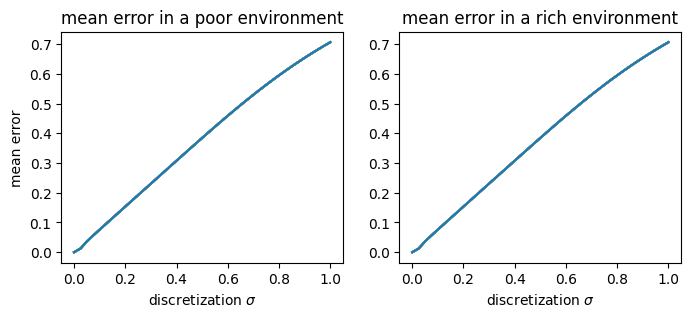

In [ ]:
#| label: fig-error-tab
#| fig-cap: "Mean error in a poor and in a rich environment as a function of reward sensitivity."

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
ax1.plot(sigmas, mean_err_poor)
ax2.plot(sigmas, mean_err_rich)
ax1.set_xlabel("discretization "+r'$\sigma$')
ax2.set_xlabel("discretization "+r'$\sigma$')
ax1.set_title("mean error in a poor environment")
ax2.set_title("mean error in a rich environment")
ax1.set_ylabel("mean error")
plt.savefig('../figs/DiscCalibr_TAB.tiff', dpi=300, bbox_inches='tight', format='tiff')
plt.show()

The reward sensitivity that minimizes the error is:

In [ ]:
idx_rich, idx_poor = np.argmin(mean_err_rich), np.argmin(mean_err_poor)
sigmas[idx_rich], sigmas[idx_poor]

(np.float64(0.0001), np.float64(0.0001))

## Errors in a stag-hunt game

Now we compare a distributional with a non-distributional agent playing the stag-hunt game defined @sec-socialdilemma , with $R = 3$, $T = 1$, $P = 0$ and $S = -2$. 

In [ ]:
env = SocialDilemma(R=3, P=0, S=-2, T=1)

Once again, we compare different reward sensitivities $\sigma$ for the distributional agent. Since the game is symmetric in agents, we compute the error assuming that the second agent's strategy equals the first agent's strategy.

In [ ]:
# List of sigmas to compare
sigmas = np.linspace(0.0001, 1., 40)

# Sample strategies
Xs = np.linspace(0.01, 0.99, 11)

In [ ]:
# Function to compute mean error
def compute_mean_error(env, Xs, sigmas, gamma, path, version):
    errors = np.zeros((len(sigmas), len(Xs)))
    for j, sigma in enumerate(sigmas):  # loop over sigmas
        print("sigma = "+str(sigma))
        # Non-distributional agent
        mae = stratSARSA(env=env, learning_rates=0.1, choice_intensities=50,
                         discount_factors=gamma, use_prefactor=True)
        
        # Distributional agent
        aei = DDRLSarsa(env, nr_reward_bins=29, discretization_sigma=sigma, 
                        learning_rates=0.1, discount_factors=gamma, 
                        Rmin=-2, Rmax=3, choice_intensities=50,
                        method="weights", wU=1, use_prefactor=True)
        
        for k, x in enumerate(Xs):  # loop over strategies
            X = np.zeros((2, 1, 2))
            X[0, 0, 0] = x
            X[0, 0, 1] = 1 - x
            # Both agents have the same strategy
            X[1, 0, 0] = x
            X[1, 0, 1] = 1 - x
            
            # TDe for dist agent
            distRPE = aei.TDerror(X, norm=True)

            # TDe for non-dist agent
            detRPE = mae.TDerror(X, norm=True)

            # Compute the error
            error = np.linalg.norm(detRPE-distRPE) 
            errors[j, k] = error

    # Compute mean error        
    mean_error = np.mean(errors, axis=-1)

    # Format into df and save
    columns = ["X="+str(x) for x in Xs]
    index = ["sigma="+str(sigma) for sigma in sigmas]
    df = pd.DataFrame(errors, index=index, columns=columns)
    df.to_csv(path+"sh_error_df_"+version+".csv")
    return mean_error

In [ ]:
# path and version
path = "../data/error_calculation/"
version = "v0"

We compute the error for a SARSA agent with discount factor $\gamma = 0.9$ and choice intensity $\beta = 50$, as in @sec-results .

In [ ]:
#| eval: false
# Compute mean error
mean_err = compute_mean_error(env, Xs, sigmas, 0.9, path, version)

sigma = 0.0001
sigma = 0.025738461538461536
sigma = 0.05137692307692308
sigma = 0.07701538461538461
sigma = 0.10265384615384615
sigma = 0.12829230769230768
sigma = 0.1539307692307692
sigma = 0.17956923076923076
sigma = 0.20520769230769229
sigma = 0.2308461538461538
sigma = 0.25648461538461537
sigma = 0.2821230769230769
sigma = 0.3077615384615384
sigma = 0.3334
sigma = 0.35903846153846153
sigma = 0.384676923076923
sigma = 0.4103153846153846
sigma = 0.43595384615384614
sigma = 0.46159230769230764
sigma = 0.4872307692307692
sigma = 0.5128692307692307
sigma = 0.5385076923076922
sigma = 0.5641461538461539
sigma = 0.5897846153846154
sigma = 0.6154230769230769
sigma = 0.6410615384615385
sigma = 0.6667
sigma = 0.6923384615384615
sigma = 0.7179769230769231
sigma = 0.7436153846153846
sigma = 0.7692538461538461
sigma = 0.7948923076923077
sigma = 0.8205307692307692
sigma = 0.8461692307692307
sigma = 0.8718076923076923
sigma = 0.8974461538461538
sigma = 0.9230846153846153
sigma = 0.9487230769230769

In [ ]:
# Extract the data
df_error = pd.read_csv(path+"sh_error_df_"+version+".csv")

# Convert to np array
mean_err = np.mean(df_error.to_numpy()[:, 1:], axis=1)

Now we can plot the error as a function of $\sigma$:

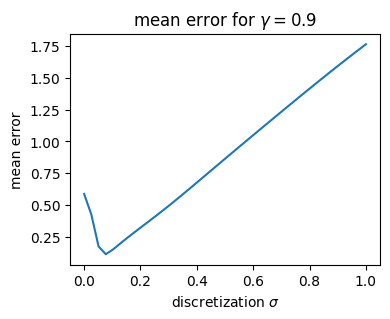

In [ ]:
#| label: fig-error-sh
#| fig-cap: "Mean error in a stag-hunt game as a function of reward sensitivity."

# Plot
fig, ax1 = plt.subplots(1, 1, figsize=(4, 3))
ax1.plot(sigmas, mean_err)
ax1.set_xlabel("discretization "+r'$\sigma$')
ax1.set_title("mean error for "+r'$\gamma=0.9$')
ax1.set_ylabel("mean error")
plt.savefig('../figs/DiscCalibr_SH.tiff', dpi=300, bbox_inches='tight', format='tiff')
plt.show()

The reward sensitivity that minimizes the error is:

In [ ]:
idx = np.argmin(mean_err)
sigmas[idx]

np.float64(0.07701538461538461)

## Errors in a risk-reward dilemma

Here, we compute the error for a distributional Actor-Critic agent playing a risk-reward dilemma as defined in @sec-rrdilemma , with $p_c = 0.2$, $p_r = 0.1$, $r_c = 0.5$, $r_r = 1$ and $r_d = 0$. 

In [ ]:
env = RiskRewardDilemma(pc=0.2, pr=0.1, rc=0.5, rr=1, rd=0)

Since the risk-reward dilemma contains 2 states, the discount factor $\gamma$ has a significant impact on the agent's strategy. Therefore, we will compute the error for an agent with a low discount factor ($\gamma=0.4$), and for an agent with a high discount factor ($\gamma=0.9$). In the degraded state, Actor-Critic agents converge to a maximally safe strategy since it is the only rational one (see @sec-results ). Therefore, we compute the error for different strategies in the prosperous state, assuming the strategy in the degraded state is always $X^{safe} = 1$.

In [ ]:
# Discount factors
gammas = [0.4, 0.9]

# List of sigmas to compare
sigmas = np.linspace(0.0001, 1., 40)

# Sample strategies
Xs = np.linspace(0.01, 0.99, 11)

In [ ]:
# Function to compute mean error
def compute_mean_error(env, Xs, sigmas, gamma, path, version):
    errors = np.zeros((len(sigmas), len(Xs)))
    for j, sigma in enumerate(sigmas):  # loop over sigmas
        print("sigma = "+str(sigma))
        # Non-distributional agent
        mae = stratAC(env=env, learning_rates=0.1, 
                      discount_factors=gamma, use_prefactor=True)
        
        # Distributional agent
        aei = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=sigma,
                              learning_rates=0.1, discount_factors=gamma, 
                              Rmin=0, Rmax=1,
                              method="weights", wU=1, use_prefactor=True)
        
        for k, x in enumerate(Xs):  # Loop over strategies
            X = np.zeros((1, 2, 2))
            X[:, 0, 0] = x
            X[:, 0, 1] = 1 - x
            X[:, 1, 0] = 1  # strategy in deg state

            # TDe for dist agent
            distRPE = aei.TDerror(X, norm=True)

            # TDe for non-dist agent
            detRPE = mae.TDerror(X, norm=True)

            # Compute error
            error = np.linalg.norm(detRPE-distRPE) 
            errors[j, k] = error

    # Compute mean error        
    mean_error = np.mean(errors, axis=-1)

    # Format into df and save
    columns = ["X="+str(x) for x in Xs]
    index = ["sigma="+str(sigma) for sigma in sigmas]
    df = pd.DataFrame(errors, index=index, columns=columns)
    df.to_csv(path+"rr_error_df_"+version+".csv")
    return mean_error

In [ ]:
# Path and version
path = "../data/error_calculation/"
version_low = "low_v1"
version_high = "high_v1"

In [ ]:
#| eval: false
# Mean error for low gamma
mean_err_low = compute_mean_error(env, Xs, sigmas, gammas[0], path, version_low)

# Mean error for high gama
mean_err_high = compute_mean_error(env, Xs, sigmas, gammas[1], path, version_high)

sigma = 0.0001
sigma = 0.025738461538461536
sigma = 0.05137692307692308
sigma = 0.07701538461538461
sigma = 0.10265384615384615
sigma = 0.12829230769230768
sigma = 0.1539307692307692
sigma = 0.17956923076923076
sigma = 0.20520769230769229
sigma = 0.2308461538461538
sigma = 0.25648461538461537
sigma = 0.2821230769230769
sigma = 0.3077615384615384
sigma = 0.3334
sigma = 0.35903846153846153
sigma = 0.384676923076923
sigma = 0.4103153846153846
sigma = 0.43595384615384614
sigma = 0.46159230769230764
sigma = 0.4872307692307692
sigma = 0.5128692307692307
sigma = 0.5385076923076922
sigma = 0.5641461538461539
sigma = 0.5897846153846154
sigma = 0.6154230769230769
sigma = 0.6410615384615385
sigma = 0.6667
sigma = 0.6923384615384615
sigma = 0.7179769230769231
sigma = 0.7436153846153846
sigma = 0.7692538461538461
sigma = 0.7948923076923077
sigma = 0.8205307692307692
sigma = 0.8461692307692307
sigma = 0.8718076923076923
sigma = 0.8974461538461538
sigma = 0.9230846153846153
sigma = 0.9487230769230769

In [ ]:
# Extract the data
df_error_low = pd.read_csv(path+"rr_error_df_"+version_low+".csv")
df_error_high = pd.read_csv(path+"rr_error_df_"+version_high+".csv")

# Convert to np array
mean_err_low = np.mean(df_error_low.to_numpy()[:, 1:], axis=1)
mean_err_high = np.mean(df_error_high.to_numpy()[:, 1:], axis=1)

Now we can plot the error for both values of $\gamma$:

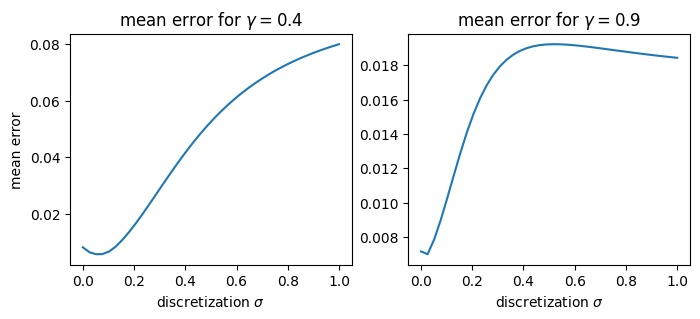

In [ ]:
#| label: fig-error-rr
#| fig-cap: "Mean error in a risk-reward dilemma as a function of reward sensitivity."

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
ax1.plot(sigmas, mean_err_low)
ax2.plot(sigmas, mean_err_high)
ax1.set_xlabel("discretization "+r'$\sigma$')
ax2.set_xlabel("discretization "+r'$\sigma$')
ax1.set_title("mean error for "+r'$\gamma=0.4$')
ax2.set_title("mean error for "+r'$\gamma=0.9$')
ax1.set_ylabel("mean error")
plt.savefig('../figs/DiscCalibr_RR.tiff', dpi=300, bbox_inches='tight', format='tiff')
plt.show()

The reward sensitivity that minimizes the error for low discount factor is:

In [ ]:
idx = np.argmin(mean_err_low)
sigmas[idx]

np.float64(0.05137692307692308)

And for high discount factor:

In [ ]:
idx = np.argmin(mean_err_high)
sigmas[idx]

np.float64(0.025738461538461536)

## Effect of the number of reward neurons

Here we investigate how the mean error depends on the number of reward neurons $N$, with $\sigma$ fixed at the value calibrated for each environment. We use a coarse grid of neuron counts spanning a range around the manuscript value of $N=29$.

In [ ]:
import time

# Coarse grid of neuron counts
neuron_counts = [5, 9, 13, 17, 21, 25, 29, 35, 41, 51]

# Calibrated sigmas (manuscript values)
sigma_tab   = 0.0001  # two-armed bandit (poor and rich)
sigma_sh    = 0.08    # stag-hunt
sigma_rr_lo = 0.05   # risk-reward dilemma, gamma=0.4
sigma_rr_hi = 0.05   # risk-reward dilemma, gamma=0.9

# Explicit environment instances — avoids depending on the global `env`
# which is overwritten across sections above
env_sh = SocialDilemma(R=3, P=0, S=-2, T=1)
env_rr = RiskRewardDilemma(pc=0.2, pr=0.1, rc=0.5, rr=1, rd=0)

# Sample strategies (same as above)
Xs = np.linspace(0.01, 0.99, 11)

# Path for saving results
path = "../data/error_calculation/"


### Two-armed bandit task

In [ ]:
#| eval: false
# Two-armed bandit: vary neuron count with sigma fixed at calibrated value

def neurons_mean_error_tab(env, Xs, sigma, neuron_counts, Rmin, Rmax, path, version):
    errors = np.zeros((len(neuron_counts), len(Xs)))
    times  = np.zeros(len(neuron_counts))
    for j, N in enumerate(neuron_counts):
        print(f"N = {N}")
        t0  = time.time()
        mae = stratSARSA(env=env, learning_rates=0.1,
                         discount_factors=0, choice_intensities=4., use_prefactor=True)
        aei = DDRLSarsa(env, nr_reward_bins=N, discretization_sigma=sigma,
                        learning_rates=0.1, discount_factors=0,
                        choice_intensities=4, Rmin=Rmin, Rmax=Rmax,
                        method="weights", wU=1, use_prefactor=True)
        for k, x in enumerate(Xs):
            X = np.zeros((1, 1, 2))
            X[:, :, 0] = x
            X[:, :, 1] = 1 - x
            distRPE = aei.TDerror(X, norm=True)
            detRPE  = mae.TDerror(X, norm=True)
            errors[j, k] = np.linalg.norm(detRPE - distRPE)
        times[j] = time.time() - t0
    columns = ["X=" + str(x) for x in Xs]
    index   = ["N=" + str(N) for N in neuron_counts]
    pd.DataFrame(errors, index=index, columns=columns).to_csv(path + "neurons_tab_" + version + ".csv")
    pd.DataFrame({'time_s': times}, index=index).to_csv(path + "neurons_tab_times_" + version + ".csv")
    return np.mean(errors, axis=-1), times

mean_neurons_poor, times_poor = neurons_mean_error_tab(env_poor, Xs, sigma_tab, neuron_counts, -1, 1, path, "poor_v1")
mean_neurons_rich, times_rich = neurons_mean_error_tab(env_rich, Xs, sigma_tab, neuron_counts, -1, 1, path, "rich_v1")

N = 5


N = 9
N = 13
N = 17
N = 21
N = 25
N = 29
N = 35
N = 41
N = 51
N = 5
N = 9
N = 13
N = 17
N = 21
N = 25
N = 29
N = 35
N = 41
N = 51


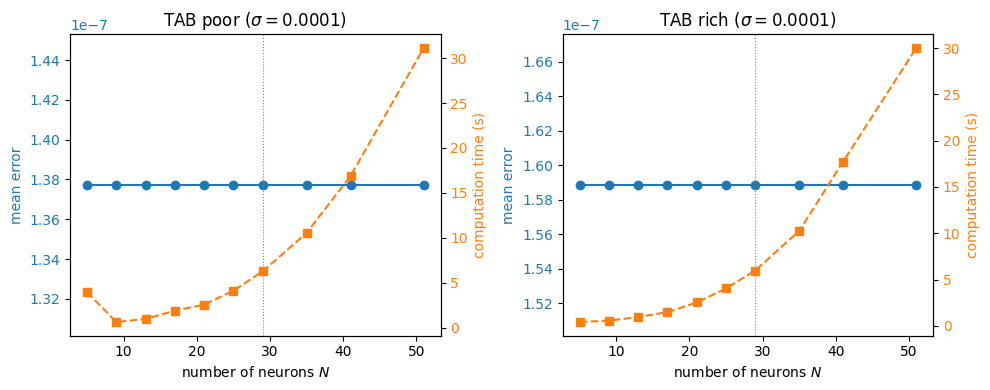

In [ ]:
# Two-armed bandit: load results and plot error + computation time vs N

mean_neurons_poor = np.mean(pd.read_csv(path + "neurons_tab_poor_v1.csv").to_numpy()[:, 1:], axis=1)
mean_neurons_rich = np.mean(pd.read_csv(path + "neurons_tab_rich_v1.csv").to_numpy()[:, 1:], axis=1)
times_poor = pd.read_csv(path + "neurons_tab_times_poor_v1.csv")["time_s"].to_numpy()
times_rich = pd.read_csv(path + "neurons_tab_times_rich_v1.csv")["time_s"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, data, times, title in zip(
    axes,
    [mean_neurons_poor, mean_neurons_rich],
    [times_poor,        times_rich],
    [f"TAB poor ($\sigma={sigma_tab}$)", f"TAB rich ($\sigma={sigma_tab}$)"],
):
    color_err  = "C0"
    color_time = "C1"
    ax.plot(neuron_counts, data, marker='o', color=color_err, label="mean error")
    ax.axvline(29, color='gray', linestyle=':', linewidth=0.8)
    ax.set_xlabel("number of neurons $N$")
    ax.set_ylabel("mean error", color=color_err)
    ax.tick_params(axis='y', labelcolor=color_err)
    ax.set_title(title)
    ax2 = ax.twinx()
    ax2.plot(neuron_counts, times, marker='s', color=color_time, linestyle='--', label="time (s)")
    ax2.set_ylabel("computation time (s)", color=color_time)
    ax2.tick_params(axis='y', labelcolor=color_time)

plt.savefig('../figs/NeuronCalibr_TAB.tiff', dpi=300, bbox_inches='tight', format='tiff')
plt.tight_layout()
plt.show()

### Stag-hunt game

In [ ]:
#| eval: false
# Stag-hunt: vary neuron count with sigma fixed at calibrated value

def neurons_mean_error_sh(env, Xs, sigma, neuron_counts, gamma, path, version):
    errors = np.zeros((len(neuron_counts), len(Xs)))
    times  = np.zeros(len(neuron_counts))
    for j, N in enumerate(neuron_counts):
        print(f"N = {N}")
        t0  = time.time()
        mae = stratSARSA(env=env, learning_rates=0.1, choice_intensities=50,
                         discount_factors=gamma, use_prefactor=True)
        aei = DDRLSarsa(env, nr_reward_bins=N, discretization_sigma=sigma,
                        learning_rates=0.1, discount_factors=gamma,
                        Rmin=-2, Rmax=3, choice_intensities=50,
                        method="weights", wU=1, use_prefactor=True)
        for k, x in enumerate(Xs):
            X = np.zeros((2, 1, 2))
            X[0, 0, 0] = x;  X[0, 0, 1] = 1 - x
            X[1, 0, 0] = x;  X[1, 0, 1] = 1 - x
            distRPE = aei.TDerror(X, norm=True)
            detRPE  = mae.TDerror(X, norm=True)
            errors[j, k] = np.linalg.norm(detRPE - distRPE)
        times[j] = time.time() - t0
    columns = ["X=" + str(x) for x in Xs]
    index   = ["N=" + str(N) for N in neuron_counts]
    pd.DataFrame(errors, index=index, columns=columns).to_csv(path + "neurons_sh_" + version + ".csv")
    pd.DataFrame({'time_s': times}, index=index).to_csv(path + "neurons_sh_times_" + version + ".csv")
    return np.mean(errors, axis=-1), times

mean_neurons_sh, times_sh = neurons_mean_error_sh(env_sh, Xs, sigma_sh, neuron_counts, 0.9, path, "v0")

N = 5
N = 9
N = 13
N = 17
N = 21
N = 25
N = 29
N = 35
N = 41
N = 51


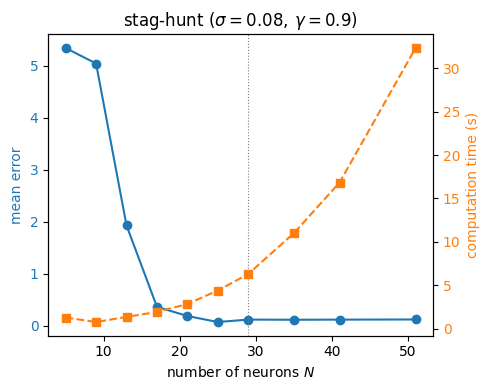

In [ ]:
# Stag-hunt: load results and plot error + computation time vs N

mean_neurons_sh = np.mean(pd.read_csv(path + "neurons_sh_v0.csv").to_numpy()[:, 1:], axis=1)
times_sh = pd.read_csv(path + "neurons_sh_times_v0.csv")["time_s"].to_numpy()

fig, ax = plt.subplots(1, 1, figsize=(5, 4))
color_err  = "C0"
color_time = "C1"
ax.plot(neuron_counts, mean_neurons_sh, marker='o', color=color_err)
ax.axvline(29, color='gray', linestyle=':', linewidth=0.8)
ax.set_xlabel("number of neurons $N$")
ax.set_ylabel("mean error", color=color_err)
ax.tick_params(axis='y', labelcolor=color_err)
ax.set_title(f"stag-hunt ($\sigma={sigma_sh},\,\gamma=0.9$)")
ax2 = ax.twinx()
ax2.plot(neuron_counts, times_sh, marker='s', color=color_time, linestyle='--')
ax2.set_ylabel("computation time (s)", color=color_time)
ax2.tick_params(axis='y', labelcolor=color_time)
plt.savefig('../figs/NeuronCalibr_SH.tiff', dpi=300, bbox_inches='tight', format='tiff')
plt.tight_layout()
plt.show()



### Risk-reward dilemma

In [ ]:
#| eval: false
# Risk-reward dilemma: vary neuron count with sigma fixed at calibrated value (per gamma)

def neurons_mean_error_rr(env, Xs, sigma, neuron_counts, gamma, path, version):
    errors = np.zeros((len(neuron_counts), len(Xs)))
    times  = np.zeros(len(neuron_counts))
    for j, N in enumerate(neuron_counts):
        print(f"N = {N}")
        t0  = time.time()
        mae = stratAC(env=env, learning_rates=0.1,
                      discount_factors=gamma, use_prefactor=True)
        aei = DDRLActorCritic(env, nr_reward_bins=N, discretization_sigma=sigma,
                              learning_rates=0.1, discount_factors=gamma,
                              Rmin=0, Rmax=1,
                              method="weights", wU=1, use_prefactor=True)
        for k, x in enumerate(Xs):
            X = np.zeros((1, 2, 2))
            X[:, 0, 0] = x;  X[:, 0, 1] = 1 - x
            X[:, 1, 0] = 1
            distRPE = aei.TDerror(X, norm=True)
            detRPE  = mae.TDerror(X, norm=True)
            errors[j, k] = np.linalg.norm(detRPE - distRPE)
        times[j] = time.time() - t0
    columns = ["X=" + str(x) for x in Xs]
    index   = ["N=" + str(N) for N in neuron_counts]
    pd.DataFrame(errors, index=index, columns=columns).to_csv(path + "neurons_rr_" + version + ".csv")
    pd.DataFrame({'time_s': times}, index=index).to_csv(path + "neurons_rr_times_" + version + ".csv")
    return np.mean(errors, axis=-1), times

mean_neurons_rr_lo, times_rr_lo = neurons_mean_error_rr(env_rr, Xs, sigma_rr_lo, neuron_counts, 0.4, path, "low_v1")
mean_neurons_rr_hi, times_rr_hi = neurons_mean_error_rr(env_rr, Xs, sigma_rr_hi, neuron_counts, 0.9, path, "high_v1")

N = 5
N = 9
N = 13
N = 17
N = 21
N = 25
N = 29
N = 35
N = 41
N = 51
N = 5
N = 9
N = 13
N = 17
N = 21
N = 25
N = 29
N = 35
N = 41
N = 51


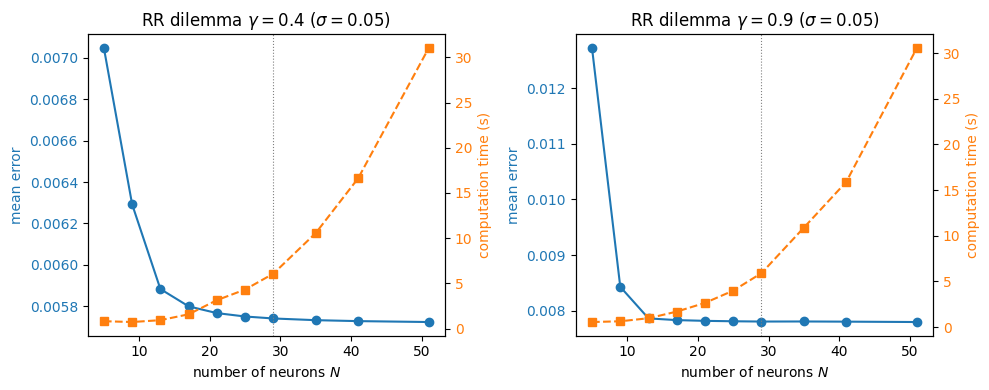

In [ ]:
# Risk-reward dilemma: load results and plot error + computation time vs N

mean_neurons_rr_lo = np.mean(pd.read_csv(path + "neurons_rr_low_v1.csv").to_numpy()[:, 1:], axis=1)
mean_neurons_rr_hi = np.mean(pd.read_csv(path + "neurons_rr_high_v1.csv").to_numpy()[:, 1:], axis=1)
times_rr_lo = pd.read_csv(path + "neurons_rr_times_low_v1.csv")["time_s"].to_numpy()
times_rr_hi = pd.read_csv(path + "neurons_rr_times_high_v1.csv")["time_s"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, data, times, title in zip(
    axes,
    [mean_neurons_rr_lo, mean_neurons_rr_hi],
    [times_rr_lo,        times_rr_hi],
    [f"RR dilemma $\gamma=0.4$ ($\sigma={sigma_rr_lo}$)", f"RR dilemma $\gamma=0.9$ ($\sigma={sigma_rr_hi}$)"],
):
    color_err  = "C0"
    color_time = "C1"
    ax.plot(neuron_counts, data, marker='o', color=color_err)
    ax.axvline(29, color='gray', linestyle=':', linewidth=0.8)
    ax.set_xlabel("number of neurons $N$")
    ax.set_ylabel("mean error", color=color_err)
    ax.tick_params(axis='y', labelcolor=color_err)
    ax.set_title(title)
    ax2 = ax.twinx()
    ax2.plot(neuron_counts, times, marker='s', color=color_time, linestyle='--')
    ax2.set_ylabel("computation time (s)", color=color_time)
    ax2.tick_params(axis='y', labelcolor=color_time)

plt.savefig('../figs/NeuronCalibr_SH.tiff', dpi=300, bbox_inches='tight', format='tiff')
plt.tight_layout()
plt.show()